In [1]:
!nvidia-smi

Sun Jan 11 08:49:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
%pip install svgwrite

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 3.5 MB/s eta 0:00:00


In [2]:
%%writefile design.json
{
  "garment_type": "kurti",
  "silhouette": "A-line",
  "neckline": "round",
  "sleeve": "3/4",
  "length": "knee",
  "fit": "relaxed"
}

Writing design.json


In [3]:
%%writefile geometry.py
import json

# Load design JSON
with open("design.json") as f:
    design = json.load(f)

# Canvas
CANVAS_WIDTH = 300
CANVAS_HEIGHT = 500
CENTER_X = CANVAS_WIDTH // 2
TOP_Y = 60

# ---- Attribute → Geometry Mappings ---- #

LENGTH_MAP = {
    "short": 260,
    "knee": 340,
    "long": 420
}

FIT_MAP = {
    "regular": 70,
    "relaxed": 90
}

SILHOUETTE_EXTRA_WIDTH = {
    "straight": 0,
    "A-line": 60
}

SLEEVE_MAP = {
    "sleeveless": 0,
    "short": 30,
    "3/4": 55,
    "long": 80
}

NECK_MAP = {
    "round": {"radius": 12},
    "v": {"depth": 20},
    "square": {"width": 24}
}

# ---- Compute Geometry ---- #

body_height = LENGTH_MAP[design["length"]]
top_width = FIT_MAP[design["fit"]]
bottom_width = top_width + SILHOUETTE_EXTRA_WIDTH[design["silhouette"]]
sleeve_length = SLEEVE_MAP[design["sleeve"]]
neck_params = NECK_MAP[design["neckline"]]

# ---- Final Geometry Object ---- #

geometry = {
    "canvas_width": CANVAS_WIDTH,
    "canvas_height": CANVAS_HEIGHT,
    "center_x": CENTER_X,
    "top_y": TOP_Y,
    "body_height": body_height,
    "top_width": top_width,
    "bottom_width": bottom_width,
    "sleeve_length": sleeve_length,
    "neck": neck_params
}

print("Geometry values:", geometry)

Writing geometry.py


In [4]:
%%writefile sketch.py
import svgwrite

# Mock geometry data for demonstration
geometry = {
    "canvas_width": 500, "canvas_height": 800,
    "center_x": 250, "top_y": 100,
    "shoulder_w": 180, "waist_w": 140, "bottom_w": 260,
    "body_h": 450, "sleeve_len": 120, "neck_depth": 40
}

dwg = svgwrite.Drawing("modern_kurti.svg", size=(geometry["canvas_width"], geometry["canvas_height"]))

cx = geometry["center_x"]
ty = geometry["top_y"]
sw = geometry["shoulder_w"] / 2
ww = geometry["waist_w"] / 2
bw = geometry["bottom_w"] / 2
bh = geometry["body_h"]
sl = geometry["sleeve_len"]

# ---- DYNAMIC PATH POINTS ---- #
# Defining key landmarks for a curved silhouette
p = {
    "neck_l": (cx - 40, ty),
    "neck_r": (cx + 40, ty),
    "sh_l": (cx - sw, ty + 10), # Slight shoulder slope
    "sh_r": (cx + sw, ty + 10),
    "arm_l": (cx - sw + 10, ty + 80),
    "arm_r": (cx + sw - 10, ty + 80),
    "waist_l": (cx - ww, ty + bh * 0.4),
    "waist_r": (cx + ww, ty + bh * 0.4),
    "hem_l": (cx - bw, ty + bh),
    "hem_r": (cx + bw, ty + bh)
}

# ---- MODERN SILHOUETTE (BODY) ---- #
# Using Bezier Curves (Q for quadratic, C for cubic) for the waist and flare
body_path = dwg.path(d=f"M {p['sh_l'][0]},{p['sh_l'][1]}", stroke="black", fill="none", stroke_width=2)
body_path.push(f"L {p['neck_l'][0]} {p['neck_l'][1]}") # Shoulder to neck
body_path.push(f"Q {cx} {ty + geometry['neck_depth']}, {p['neck_r'][0]} {p['neck_r'][1]}") # Curved Neckline
body_path.push(f"L {p['sh_r'][0]} {p['sh_r'][1]}") # Neck to shoulder
body_path.push(f"L {p['arm_r'][0]} {p['arm_r'][1]}") # Armhole
body_path.push(f"Q {p['waist_r'][0]} {p['waist_r'][1]}, {p['hem_r'][0]} {p['hem_r'][1]}") # Curved side seam
body_path.push(f"Q {cx} {ty + bh - 20}, {p['hem_l'][0]} {p['hem_l'][1]}") # High-Low Hemline
body_path.push(f"Q {p['waist_l'][0]} {p['waist_l'][1]}, {p['arm_l'][0]} {p['arm_l'][1]}") # Curved side seam
body_path.push("Z")
dwg.add(body_path)

# ---- MODERN SLEEVES (Bell Sleeves) ---- #
if sl > 0:
    for side in [-1, 1]: # -1 for left, 1 for right
        start = p['sh_l'] if side == -1 else p['sh_r']
        end_inner = p['arm_l'] if side == -1 else p['arm_r']
        
        sleeve = dwg.path(d=f"M {start[0]},{start[1]}", stroke="black", fill="none", stroke_width=1.5)
        # Tapered or flared sleeve logic
        sleeve.push(f"L {start[0] + (side * 30)}, {start[1] + sl}") # Outer edge
        sleeve.push(f"L {end_inner[0] + (side * 10)}, {start[1] + sl}") # Cuff
        sleeve.push(f"L {end_inner[0]}, {end_inner[1]}") # Underarm
        dwg.add(sleeve)

# ---- FASHION DETAILS (Side Slits) ---- #
dwg.add(dwg.line(p['waist_l'], (p['waist_l'][0], p['hem_l'][1]), stroke="black", stroke_dasharray="4"))
dwg.add(dwg.line(p['waist_r'], (p['waist_r'][0], p['hem_r'][1]), stroke="black", stroke_dasharray="4"))

dwg.save()

Writing sketch.py


In [5]:
!python geometry.py
!python sketch.py

Geometry values: {'canvas_width': 300, 'canvas_height': 500, 'center_x': 150, 'top_y': 60, 'body_height': 340, 'top_width': 90, 'bottom_width': 150, 'sleeve_length': 55, 'neck': {'radius': 12}}


In [6]:
ls

design.json  geometry.py  modern_kurti.svg  sample_data/  sketch.py


In [1]:
# Install svglib and its required dependencies for the fashion project
!pip install svglib reportlab diffusers transformers accelerate controlnet_aux opencv-python pillow numpy flask flask-cors pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.4/290.4 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 71.4 MB/s eta 0:00:00


In [8]:
import torch
import cv2
import numpy as np
from PIL import Image
from svglib.svglib import svg2rlg
from reportlab.graphics import renderPM
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

# 1. LOAD THE EXISTING SVG FILE
def prepare_existing_design(svg_path="modern_kurti.svg"):
    # Check if file exists
    import os
    if not os.path.exists(svg_path):
        print(f"❌ Error: {svg_path} not found!")
        return False
    
    # Convert existing SVG to PNG for the AI processing
    drawing = svg2rlg(svg_path)
    renderPM.drawToFile(drawing, "hint.png", fmt="PNG")
    print(f"✅ Existing {svg_path} loaded and converted to AI hint.")
    return True

# 2. LOAD THE AI MODELS INTO T4 VRAM
def load_ai_models():
    print("🚀 Loading models into Tesla T4... this takes a moment.")
    controlnet = ControlNetModel.from_pretrained(
        "lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16
    )
    pipe = StableDiffusionControlNetPipeline.from_pretrained(
        "runwayml/stable-diffusion-v1-5", 
        controlnet=controlnet, 
        torch_dtype=torch.float16
    ).to("cuda") # Moving to your T4
    
    pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
    return pipe

# 3. GENERATE REALISTIC IMAGE
def render_design(pipe, prompt):
    # Prepare the edge map from the PNG we just created
    image = Image.open("hint.png").convert("RGB")
    image_np = np.array(image)
    
    # Canny edge detection: detects the lines of your Kurti
    canny_image = cv2.Canny(image_np, 100, 200)[:, :, None]
    canny_image = np.concatenate([canny_image] * 3, axis=2)
    canny_image = Image.fromarray(canny_image)

    print("🎨 Generating realistic image from your Kurti design...")
    result = pipe(
        prompt,
        canny_image,
        num_inference_steps=30,
        controlnet_conditioning_scale=1.0, # Keeps the AI strictly to your SVG lines
        negative_prompt="man, woman, face, blurry, lowres, bad anatomy, distorted fabric"
    ).images[0]
    
    result.save("modern_kurti_render.png")
    print("✨ Render complete! Open 'modern_kurti_render.png' to see your design.")

# --- EXECUTE ---
# Ensure your 'modern_kurti.svg' is in the same folder
if prepare_existing_design("modern_kurti.svg"):
    model_pipe = load_ai_models()
    # Updated prompt for the Kurti
    kurti_prompt = "A luxury velvet Kurti with gold embroidery details, deep emerald green, dramatic cinematic lighting, 8k professional photography"
    render_design(model_pipe, kurti_prompt)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


✅ Existing modern_kurti.svg loaded and converted to AI hint.
🚀 Loading models into Tesla T4... this takes a moment.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (16 outputs left out)

`torch_dtype` is deprecated! Use `dtype` instead!


🎨 Generating realistic image from your Kurti design...


  0%|          | 0/30 [00:00<?, ?it/s]

✨ Render complete! Open 'modern_kurti_render.png' to see your design.


In [9]:
ls

design.json  hint.png                 modern_kurti.svg  sketch.py
geometry.py  modern_kurti_render.png  sample_data/


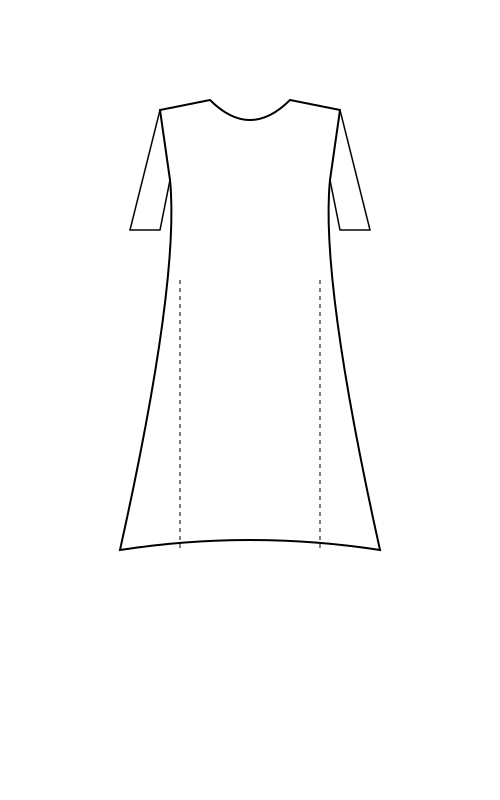

In [10]:
from IPython.display import SVG, display

# Replace 'modern_kurti.svg' with your actual filename
display(SVG(filename='modern_kurti.svg'))

--- AI GENERATED DESIGN ---


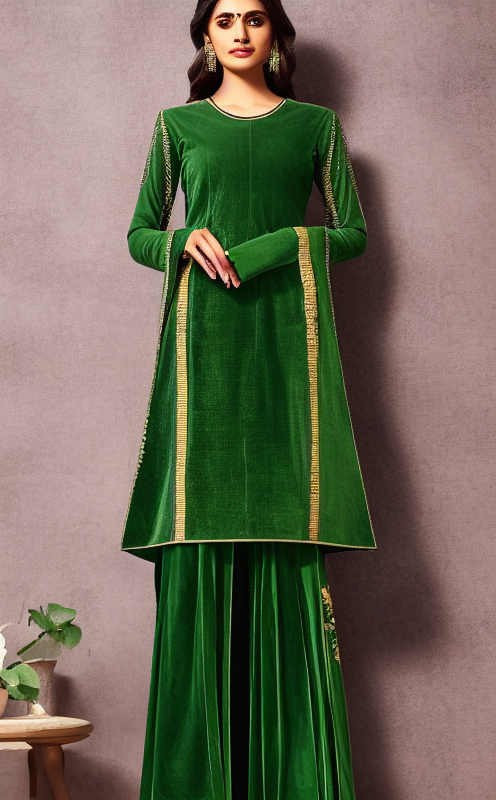

In [11]:
from IPython.display import Image, SVG, display



# View the AI Rendered PNG
print("--- AI GENERATED DESIGN ---")
display(Image(filename='modern_kurti_render.png'))

# using stable-diffusion-v1-5 (the model currenly is depricated , but useful)

In [9]:
# 1. INSTALL DEPENDENCIES
!pip install diffusers transformers accelerate opencv-python numpy flask flask-cors pyngrok

import torch
import cv2
import numpy as np
import base64
from io import BytesIO
from PIL import Image
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

# 2. LOAD MODELS (Run once)
print("🚀 Loading AI Models...")
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16
)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", 
    controlnet=controlnet, 
    torch_dtype=torch.float16
).to("cuda")
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
print("✅ Models Loaded!")

# 3. SETUP FLASK SERVER
app = Flask(__name__)
CORS(app) # Allows your Next.js app to talk to this

@app.route('/generate', methods=['POST'])
def generate():
    try:
        data = request.json
        prompt = data.get("prompt", "A fashion design")
        image_data = data.get("image") # Base64 string from frontend

        # A. Decode the frontend sketch
        header, encoded = image_data.split(",", 1)
        image_bytes = base64.b64decode(encoded)
        init_image = Image.open(BytesIO(image_bytes)).convert("RGB")
        image_np = np.array(init_image)

        # B. Create Canny Edge Map (The "Control")
        low_threshold = 100
        high_threshold = 200
        canny_image = cv2.Canny(image_np, low_threshold, high_threshold)[:, :, None]
        canny_image = np.concatenate([canny_image] * 3, axis=2)
        canny_image = Image.fromarray(canny_image)

        # C. Generate
        print(f"🎨 Generating: {prompt}")
        output = pipe(
            prompt,
            canny_image,
            num_inference_steps=30,
            controlnet_conditioning_scale=1.0, 
            negative_prompt="cropped, lowres, bad anatomy, distorted, text, watermark"
        ).images[0]

        # D. Convert output back to Base64 to send to frontend
        buffered = BytesIO()
        output.save(buffered, format="PNG")
        output_base64 = base64.b64encode(buffered.getvalue()).decode('utf-8')

        return jsonify({"status": "success", "image": f"data:image/png;base64,{output_base64}"})

    except Exception as e:
        return jsonify({"status": "error", "message": str(e)})

# 4. START THE PUBLIC TUNNEL
# IMPORTANT: You need an Ngrok Auth Token (Free). 
# Get it here: https://dashboard.ngrok.com/get-started/your-authtoken
NGROK_AUTH_TOKEN = "2vM0B4m36n5BdVFgIXqOPmS1Rsb_47BYD7LzfGdBGttGXTwY6" 
ngrok.set_auth_token(NGROK_AUTH_TOKEN)

public_url = ngrok.connect(5000).public_url
print(f"🌍 YOUR API URL IS: {public_url}")
print("COPY THIS URL INTO YOUR FRONTEND CODE!")

app.run(port=5000)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


🚀 Loading AI Models...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (30 outputs left out)

INFO:werkzeug:127.0.0.1 - - [09/Jan/2026 17:57:24] "POST /generate HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [09/Jan/2026 18:00:18] "OPTIONS /generate HTTP/1.1" 200 -


🎨 Generating: Traditional white Garad silk saree with a bold red border, paired with a red puff-sleeved blouse. Detailed gold temple jewelry, large red bindi, red alta on hands, hair neatly tied in a bun adorned with jasmine flowers.


  0%|          | 0/30 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [09/Jan/2026 18:00:34] "POST /generate HTTP/1.1" 200 -


#SDXL model

In [7]:
# 1. INSTALL DEPENDENCIES (Added safetensors and xformers)
!pip install -q diffusers transformers accelerate opencv-python numpy flask flask-cors pyngrok xformers

import torch
import cv2
import numpy as np
import base64
from io import BytesIO
from PIL import Image
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
from diffusers import StableDiffusionXLControlNetPipeline, ControlNetModel, AutoencoderKL, UniPCMultistepScheduler

# 2. LOAD SDXL MODELS (Optimized for 16GB T4)
print("🚀 Loading SDXL Models into T4 VRAM...")

# Load SDXL Canny ControlNet
controlnet = ControlNetModel.from_pretrained(
    "diffusers/controlnet-canny-sdxl-1.0", 
    torch_dtype=torch.float16
)

# Load SDXL Base Pipeline
pipe = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
).to("cuda")

# Critical Memory Optimizations for T4
pipe.enable_xformers_memory_efficient_attention()
pipe.enable_model_cpu_offload() # Moves parts to RAM when not in use to save VRAM

pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
print("✅ SDXL Models Loaded!")

# 3. SETUP FLASK SERVER
app = Flask(__name__)
CORS(app)

@app.route('/generate', methods=['POST'])
def generate():
    try:
        data = request.json
        prompt = data.get("prompt", "A high-fashion designer Kurti")
        image_data = data.get("image")

        # A. Decode the frontend sketch
        header, encoded = image_data.split(",", 1)
        image_bytes = base64.b64decode(encoded)
        init_image = Image.open(BytesIO(image_bytes)).convert("RGB")
        
        # SDXL works best at 1024x1024
        init_image = init_image.resize((1024, 1024))
        image_np = np.array(init_image)

        # B. Create Canny Edge Map
        canny_image = cv2.Canny(image_np, 100, 200)[:, :, None]
        canny_image = np.concatenate([canny_image] * 3, axis=2)
        canny_image = Image.fromarray(canny_image)

        # C. Generate (SDXL needs fewer steps with UniPC, ~25-30 is fine)
        print(f"🎨 Rendering SDXL: {prompt}")
        output = pipe(
            prompt,
            image=canny_image,
            num_inference_steps=30,
            controlnet_conditioning_scale=0.8, # 0.8 allows SDXL to be more creative with textures
            negative_prompt="low quality, blurry, distorted, watermark, signature, text, 3d render, cartoon"
        ).images[0]

        # D. Convert output back to Base64
        buffered = BytesIO()
        output.save(buffered, format="PNG")
        output_base64 = base64.b64encode(buffered.getvalue()).decode('utf-8')

        return jsonify({"status": "success", "image": f"data:image/png;base64,{output_base64}"})

    except Exception as e:
        return jsonify({"status": "error", "message": str(e)})

# 4. START THE PUBLIC TUNNEL
NGROK_AUTH_TOKEN = "2vM0B4m36n5BdVFgIXqOPmS1Rsb_47BYD7LzfGdBGttGXTwY6" 
ngrok.set_auth_token(NGROK_AUTH_TOKEN)

public_url = ngrok.connect(5000).public_url
print(f"🌍 YOUR SDXL API URL IS: {public_url}")

app.run(port=5000)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 8.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 696.3 kB/s eta 0:00:000:01m00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 3.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 104.6 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.7 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 55.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 13.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


🚀 Loading SDXL Models into T4 VRAM...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

... (23 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

: 

: 

: 

# Using SDXL-Lightining model (Stil final model)

In [1]:
# 1. INSTALL DEPENDENCIES
!pip install -q diffusers transformers accelerate opencv-python numpy flask flask-cors pyngrok xformers safetensors

import torch
import cv2
import numpy as np
import base64
from io import BytesIO
from PIL import Image
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from diffusers import (
    StableDiffusionXLControlNetPipeline, 
    ControlNetModel, 
    EulerDiscreteScheduler
)

# 2. LOAD SDXL-LIGHTNING MODELS (Corrected Safetensors Loading)
# 2. LOAD SDXL-LIGHTNING MODELS (OOM-Safe for T4)
print("🚀 Loading SDXL-Lightning into T4...")

base_model = "stabilityai/stable-diffusion-xl-base-1.0"
repo = "ByteDance/SDXL-Lightning"
ckpt = "sdxl_lightning_4step_unet.safetensors"

# Load ControlNet
controlnet = ControlNetModel.from_pretrained(
    "diffusers/controlnet-canny-sdxl-1.0", 
    torch_dtype=torch.float16
)

# Load Pipeline - DO NOT ADD .to("cuda") here!
pipe = StableDiffusionXLControlNetPipeline.from_pretrained(
    base_model, 
    controlnet=controlnet, 
    torch_dtype=torch.float16, 
    variant="fp16"
)

# Load Lightning Weights
print("📦 Downloading Lightning UNet weights...")
unet_path = hf_hub_download(repo, ckpt)
pipe.unet.load_state_dict(load_file(unet_path, device="cpu")) # Load to CPU first

# IMPORTANT: The "Smooth" Trick for T4
# This moves sub-modules to GPU one-by-one only when needed
pipe.enable_sequential_cpu_offload() 
pipe.enable_xformers_memory_efficient_attention()

pipe.scheduler = EulerDiscreteScheduler.from_config(
    pipe.scheduler.config, 
    timestep_spacing="trailing"
)

print("✅ SDXL-Lightning Ready (Memory Optimized)!")

# 3. SETUP FLASK SERVER
app = Flask(__name__)
CORS(app)

@app.route('/generate', methods=['POST'])
def generate():
    try:
        data = request.json
        prompt = data.get("prompt", "A high-fashion designer Kurti")
        image_data = data.get("image")

        # A. Decode and Resize (SDXL must be 1024x1024)
        header, encoded = image_data.split(",", 1)
        image_bytes = base64.b64decode(encoded)
        init_image = Image.open(BytesIO(image_bytes)).convert("RGB").resize((1024, 1024))
        image_np = np.array(init_image)

        # B. Create Canny Edge Map
        canny_image = cv2.Canny(image_np, 100, 200)[:, :, None]
        canny_image = np.concatenate([canny_image] * 3, axis=2)
        canny_image = Image.fromarray(canny_image)

        # C. Generate (Lightning Rules: CFG=0, Steps=4)
        print(f"⚡ Lightning Render: {prompt}")
        output = pipe(
            prompt,
            image=canny_image,
            num_inference_steps=4, 
            guidance_scale=0, 
            controlnet_conditioning_scale=0.7
        ).images[0]

        # D. Convert to Base64
        buffered = BytesIO()
        output.save(buffered, format="PNG")
        output_base64 = base64.b64encode(buffered.getvalue()).decode('utf-8')

        return jsonify({"status": "success", "image": f"data:image/png;base64,{output_base64}"})

    except Exception as e:
        return jsonify({"status": "error", "message": str(e)})

# 4. START TUNNEL
NGROK_AUTH_TOKEN = "2vM0B4m36n5BdVFgIXqOPmS1Rsb_47BYD7LzfGdBGttGXTwY6" 
ngrok.set_auth_token(NGROK_AUTH_TOKEN)
public_url = ngrok.connect(5000).public_url
print(f"🌍 API URL: {public_url}")

app.run(port=5000)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 8.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 765.6 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 154.2 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.4 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 80.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 13.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 5.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 4.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


🚀 Loading SDXL-Lightning into T4...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

... (30 outputs left out)

INFO:werkzeug:127.0.0.1 - - [11/Jan/2026 11:40:54] "POST /generate HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [11/Jan/2026 11:43:22] "OPTIONS /generate HTTP/1.1" 200 -


⚡ Lightning Render: Modern classic trench coat dress, tailored long silhouette, double-breasted front, structured lapel collar, belted waist, clean panel lines, functional pockets, minimal detailing, elegant proportions, timeless outerwear design, refined and sophisticated style.


  0%|          | 0/4 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Jan/2026 11:43:45] "POST /generate HTTP/1.1" 200 -
